In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path('../data/interim/DataCo_Cleaned_Interim.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('DataCo_Cleaned_Interim.csv')
df = pd.read_csv(DATA_PATH, encoding='latin1', low_memory=False)
print(f'Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Dataset shape: 180,519 rows x 53 columns


,ï»¿Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class


In [9]:
status = df['Order Status'].astype('string').str.strip().str.upper()
total_records = len(df)
status_summary = (status.value_counts(dropna=False)
                  .rename_axis('Order Status').reset_index(name='Count'))
status_summary['Percentage'] = (status_summary['Count'] / total_records * 100).round(2)
status_summary = status_summary.sort_values('Count', ascending=False).reset_index(drop=True)
status_summary

,Order Status,Count,Percentage
0,COMPLETE,59491,32.96
1,PENDING_PAYMENT,39832,22.07
2,PROCESSING,21902,12.13
3,PENDING,20227,11.2
4,CLOSED,19616,10.87
5,ON_HOLD,9804,5.43
6,SUSPECTED_FRAUD,4062,2.25
7,CANCELED,3692,2.05
8,PAYMENT_REVIEW,1893,1.05


In [10]:
delivery = df['Delivery Status'].astype('string').str.strip()
cancel_mask = status.eq('CANCELED').fillna(False)
shipping_canceled_mask = delivery.str.casefold().eq('shipping canceled').fillna(False)
canceled_count = int(cancel_mask.sum())
shipping_canceled_count = int(shipping_canceled_mask.sum())
cancellation_summary = pd.DataFrame([
    {'Metric': 'Total records', 'Count': total_records, 'Percentage': 100.0},
    {'Metric': 'Order Status = CANCELED', 'Count': canceled_count, 'Percentage': round(canceled_count / total_records * 100, 2)},
    {'Metric': 'Delivery Status = Shipping canceled', 'Count': shipping_canceled_count, 'Percentage': round(shipping_canceled_count / total_records * 100, 2)},
    {'Metric': 'CANCELED orders also labeled Shipping canceled', 'Count': int((cancel_mask & shipping_canceled_mask).sum()), 'Percentage': round((cancel_mask & shipping_canceled_mask).sum() / max(canceled_count, 1) * 100, 2)},
])
cancellation_summary

,Metric,Count,Percentage
0,Total records,180519,100.00
1,Order Status = CANCELED,3692,2.05
2,Delivery Status = Shipping canceled,7754,4.30
3,CANCELED orders also labeled Shipping canceled,3692,100.00


In [11]:
canceled = df.loc[cancel_mask].copy()
relevant_fields = ['Delivery Status', 'Days for shipping (real)', 'shipping date (DateOrders)', 'order date (DateOrders)', 'Shipping Mode', 'Order Id']
checks = []
for col in relevant_fields:
    missing = int(canceled[col].isna().sum())
    checks.append({'Check': f'Missing values in {col}', 'Count': missing, 'Result': 'PASS' if missing == 0 else 'REVIEW'})
order_dates = pd.to_datetime(canceled['order date (DateOrders)'], errors='coerce')
shipping_dates = pd.to_datetime(canceled['shipping date (DateOrders)'], errors='coerce')
checks += [
    {'Check': 'Unparseable order dates', 'Count': int(order_dates.isna().sum()), 'Result': 'PASS' if order_dates.notna().all() else 'REVIEW'},
    {'Check': 'Unparseable shipping dates', 'Count': int(shipping_dates.isna().sum()), 'Result': 'PASS' if shipping_dates.notna().all() else 'REVIEW'},
    {'Check': 'Shipping date before order date', 'Count': int((shipping_dates < order_dates).sum()), 'Result': 'PASS' if not (shipping_dates < order_dates).any() else 'REVIEW'},
    {'Check': 'CANCELED orders not labeled Shipping canceled', 'Count': int((cancel_mask & ~shipping_canceled_mask).sum()), 'Result': 'PASS' if (cancel_mask & ~shipping_canceled_mask).sum() == 0 else 'REVIEW'},
]
data_checks = pd.DataFrame(checks)
data_checks

,Check,Count,Result
0,Missing values in Delivery Status,0,PASS
1,Missing values in Days for shipping (real),0,PASS
2,Missing values in shipping date (DateOrders),0,PASS
3,Missing values in order date (DateOrders),0,PASS
4,Missing values in Shipping Mode,0,PASS
5,Missing values in Order Id,0,PASS
6,Unparseable order dates,0,PASS
7,Unparseable shipping dates,0,PASS
8,Shipping date before order date,0,PASS
9,CANCELED orders not labeled Shipping canceled,0,PASS


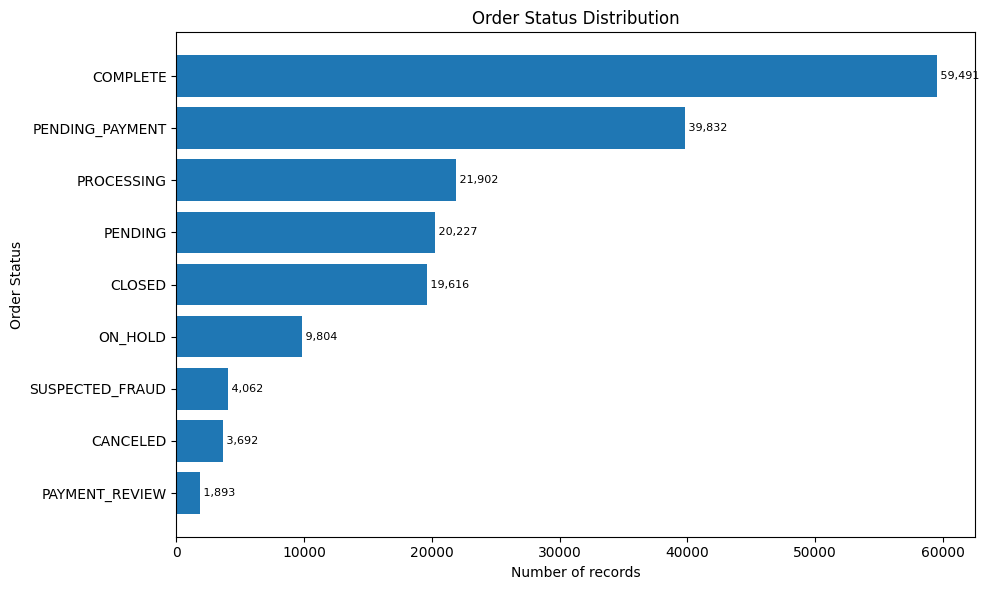

In [12]:
plot_data = status_summary.sort_values('Count', ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data['Order Status'].astype(str), plot_data['Count'])
ax.set_title('Order Status Distribution')
ax.set_xlabel('Number of records')
ax.set_ylabel('Order Status')
for i, value in enumerate(plot_data['Count']):
    ax.text(value, i, f' {value:,}', va='center', fontsize=8)
fig.tight_layout()
plt.show()

In [13]:
status_delivery_crosstab = pd.crosstab(status.fillna('MISSING'), delivery.fillna('MISSING'))
status_delivery_crosstab

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Order Status,,,,
CANCELED,0,0,3692,0
CLOSED,4809,11109,0,3698
COMPLETE,14136,34199,0,11156
ON_HOLD,2413,5450,0,1941
PAYMENT_REVIEW,420,1082,0,391
PENDING,4857,11712,0,3658
PENDING_PAYMENT,9588,22922,0,7322
PROCESSING,5369,12503,0,4030
SUSPECTED_FRAUD,0,0,4062,0


In [14]:
print(f'Total records: {total_records:,}')
print(f'CANCELED orders: {canceled_count:,} ({canceled_count / total_records * 100:.2f}%)')
print(f'Shipping canceled delivery labels: {shipping_canceled_count:,} ({shipping_canceled_count / total_records * 100:.2f}%)')
print(f'SUSPECTED_FRAUD with Shipping canceled: {int(((status == 'SUSPECTED_FRAUD') & shipping_canceled_mask).sum()):,}')
print(f'Missing values in checked fields among canceled orders: {int(canceled[relevant_fields].isna().sum().sum()):,}')

Total records: 180,519
CANCELED orders: 3,692 (2.05%)
Shipping canceled delivery labels: 7,754 (4.30%)
SUSPECTED_FRAUD with Shipping canceled: 4,062
Missing values in checked fields among canceled orders: 0
